In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

validations = pd.read_csv("data/interim/validations.csv")
routes = pd.read_csv("data/interim/routes.csv")
vehicles = pd.read_csv("data/interim/vehicles.csv")
stops = pd.read_csv("data/interim/stops.csv")

print(validations.shape, routes.shape, vehicles.shape, stops.shape)

(67407, 21) (60, 6) (180, 7) (400, 5)


In [2]:
fact = validations.merge(routes, on="route_id", how="left")
fact= fact.merge(vehicles, on="vehicle_id", how="left")
fact= fact.merge(stops, on="stop_id", how= "left")

print(f"Fact table shape: {fact.shape}")


Fact table shape: (67407, 36)


#### We used left joins throughout, keeping 'validations' as the base table. 'Routes', 'Vehicles' and 'Stops' act as lookup tables-a left join enriches each validation with route, vehicle and stop details without risking dropping or duplicating validation rows

In [3]:
assert fact.shape[0]== validations.shape[0], (
    f"Row count mismatch after joining"
    f"Expected {validations.shape[0]}, got {fact.shape[0]}"
    f"This likely means duplicate keys in routes/vehichles/stops caused a fan-out."
)
print("Row count assertion passed- no fan-out detected")

Row count assertion passed- no fan-out detected


In [4]:
print(routes["route_id"].duplicated().sum())
print(vehicles["vehicle_id"].duplicated().sum())
print(stops["stop_id"].duplicated().sum())

0
0
0


In [5]:
def add_load_factor(df):
    df= df.copy()

    df["load_factor"]= df["passenger_count"] / df["capacity"]

    print("Derived load_factor as passenger_count / capacity")
    return df
fact = add_load_factor(fact)

Derived load_factor as passenger_count / capacity


In [6]:
print(fact["load_factor"].describe())
print((fact["capacity"]==0).sum())
print(fact["capacity"].isna().sum())

count    67407.000000
mean         0.009598
std          0.006752
min         -0.050000
25%          0.004975
50%          0.008475
75%          0.014286
max          0.050000
Name: load_factor, dtype: float64
0
0


In [7]:
print(fact["capacity"].describe())
print(fact["passenger_count"].describe())

count    67407.000000
mean       175.342116
std        153.127778
min         60.000000
25%         72.000000
50%        121.000000
75%        201.000000
max        690.000000
Name: capacity, dtype: float64
count    67407.000000
mean         1.077648
std          0.436272
min         -3.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          3.000000
Name: passenger_count, dtype: float64


In [8]:
trip_level= fact.groupby(["vehicle_id", "date"]).agg(
    total_passengers= ("passenger_count","sum"),
    capacity= ("capacity","first")
).reset_index()

trip_level["load_factor"]= trip_level["total_passengers"] / trip_level["capacity"]

print(trip_level["load_factor"].describe())

count    30147.000000
mean         0.021460
std          0.017340
min         -0.064103
25%          0.009259
50%          0.016043
75%          0.028986
max          0.163934
Name: load_factor, dtype: float64


In [9]:
fact_valid= fact[fact["is_reversed"]==False]

In [10]:
[c for c in fact.columns if "revers" in c.lower()]

['is_reversed']

In [11]:
[c for c in validations.columns if "revers" in c.lower()]

['is_reversed']

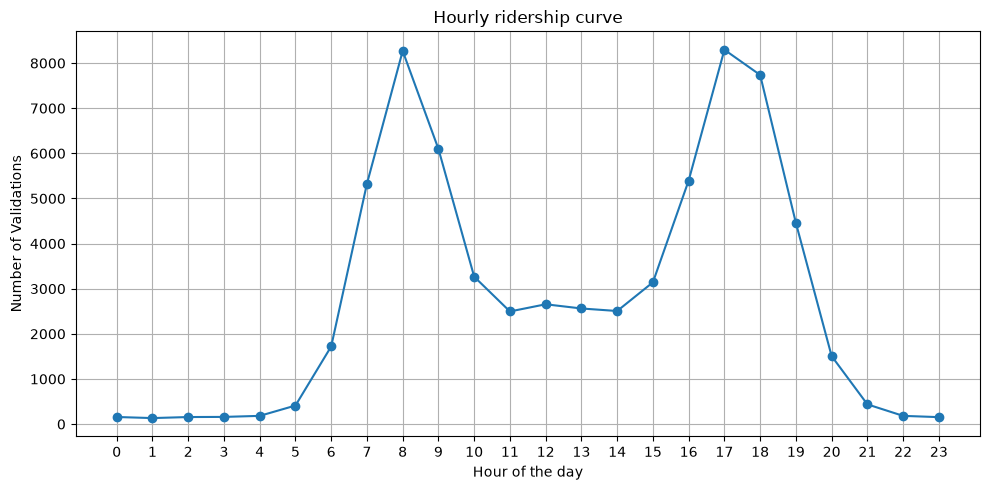

In [12]:
hourly= fact.groupby("hour").size()

plt.figure(figsize=(10,5))
hourly.plot(kind= "line", marker="o")
plt.title("Hourly ridership curve")
plt.xlabel("Hour of the day")
plt.ylabel("Number of Validations")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

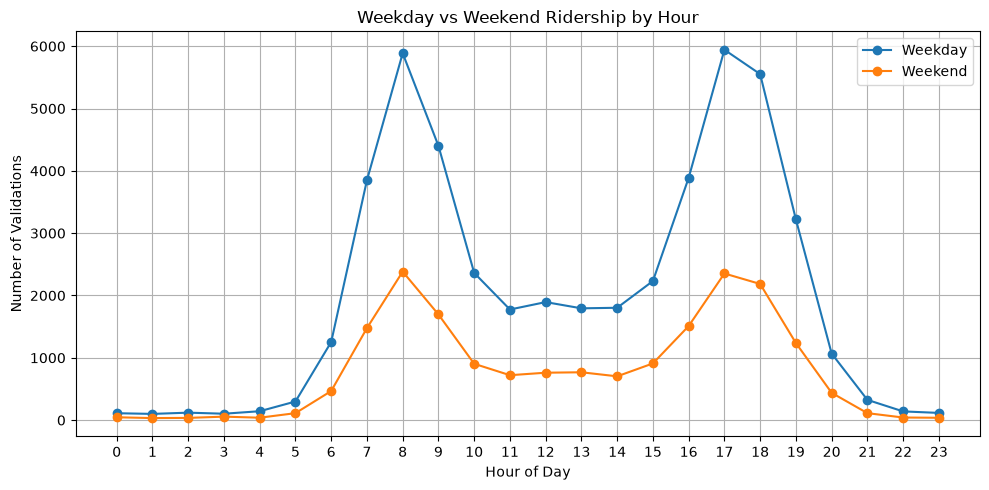

In [13]:
weekday_weekend = (
    fact.groupby(["is_weekend", "hour"])
    .size()
    .reset_index(name="validations")
)

plt.figure(figsize=(10, 5))
for is_weekend, group in weekday_weekend.groupby("is_weekend"):
    label= "Weekend" if is_weekend else "Weekday"
    plt.plot(group["hour"], group["validations"], marker="o", label=label)
    

plt.title("Weekday vs Weekend Ridership by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Validations")
plt.xticks(range(0,24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


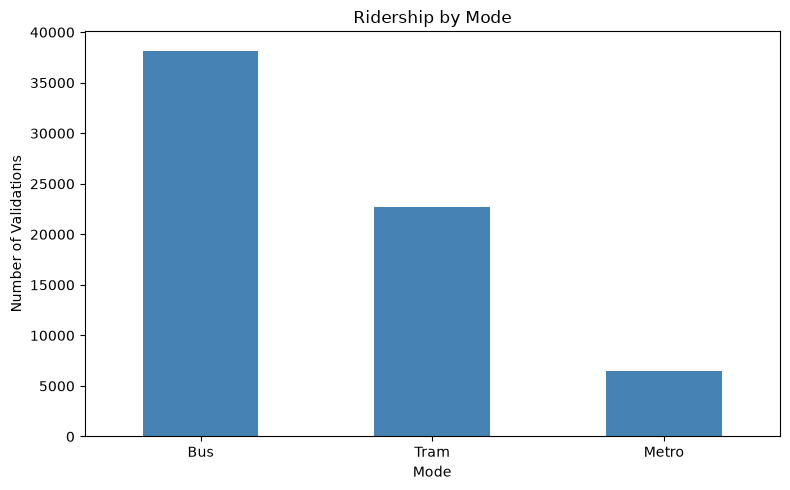

In [14]:
mode_counts= fact["mode"].value_counts()

plt.figure(figsize=(8,5))
mode_counts.plot(kind="bar", color="steelblue")
plt.title("Ridership by Mode")
plt.xlabel("Mode")
plt.ylabel("Number of Validations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

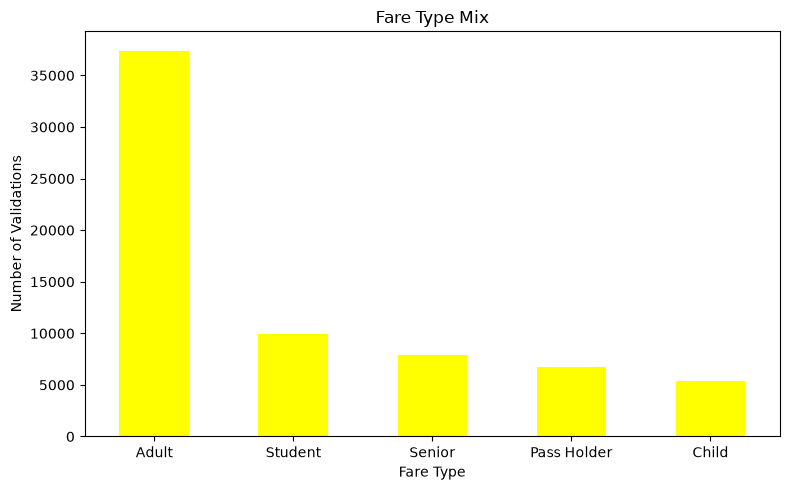

In [15]:
fare_counts= fact["fare_type"].value_counts()

plt.figure(figsize=(8,5))
fare_counts.plot(kind="bar", color="yellow")
plt.title("Fare Type Mix")
plt.xlabel("Fare Type")
plt.ylabel("Number of Validations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

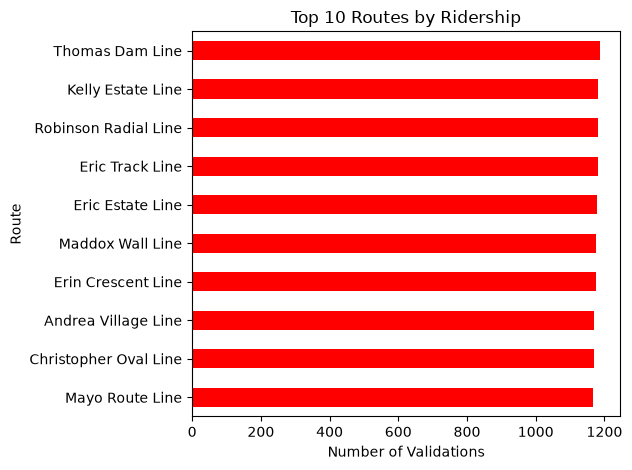

In [16]:
top_routes=fact["route_name"].value_counts().head(10)
plt.Figure(figsize=(10,6))
top_routes.plot(kind="barh", color="red")
plt.title("Top 10 Routes by Ridership")
plt.xlabel("Number of Validations")
plt.ylabel("Route")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [17]:
fact= fact.rename(columns={"district_x": "route_district", 
                           "district__y":"stop_district"}
                           )

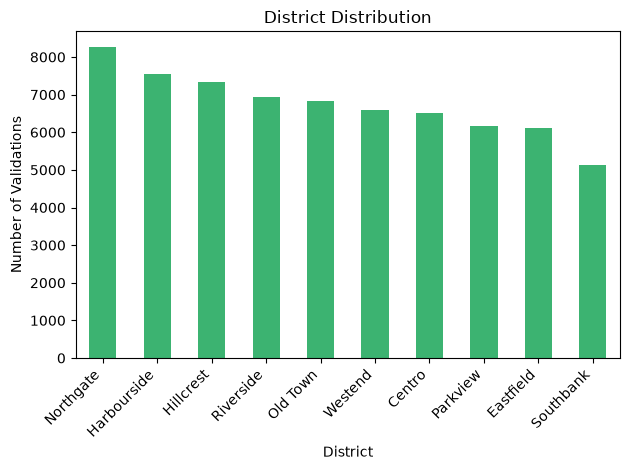

In [18]:
district_counts= fact["district_y"].value_counts()

plt.Figure(figsize=(10,6))
district_counts.plot(kind="bar", color= "mediumseagreen")
plt.title("District Distribution")
plt.xlabel("District")
plt.ylabel("Number of Validations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [19]:
[c for c in fact.columns if "distr" in c.lower()]

['route_district', 'district_y']

### Three things i learned
1. Route district and stop district rarely match - only about 9.6% of validations have a matching route_district and stop_district. 
2. Weekend ridership is far flatter than weekday ridership.
3. Top routes are remarkably close in popularity- the top 10 routes by ridership are all clustered within a narrow range, rather then one or two routes dominatin overall demand.

In [22]:
fact.to_parquet("data/interim/fact_validations.parquet", index=False)
print("Saved fact table to data/interim/fact_validations.parquet")

Saved fact table to data/interim/fact_validations.parquet


In [23]:
fact_to_save= fact.copy()
for col in fact_to_save.select_dtypes(include="string").columns:
    fact_to_save[col]= fact_to_save[col].astype(object)
fact_to_save.to_parquet("data/interim/fact_validations.parquet", index=False)

print("Saved fact table to data/interim/fact_validations.parquet")

Saved fact table to data/interim/fact_validations.parquet
